# 第04回 B｜振子の動きからパラメータを求める
[Aで作ったモデル](https://colab.research.google.com/drive/1zJkIM1h1L9vUq7i0Lh4q-iRpZC7evbGe)を実物に近づけるには、質量や長さに加え、慣性や摩擦の値が必要です。

**データを作る → 運動方程式を読む → 式の意味を説明する → パラメータを求める。**

今回は配布プログラムを実行し、式と計算の対応を理解します。

## 1｜実験データを準備する
支点を固定した棒を**水平90°・静止から離し**、10秒間の角度と角速度を記録します。角度は上向き0°、水平90°、真下180°です。

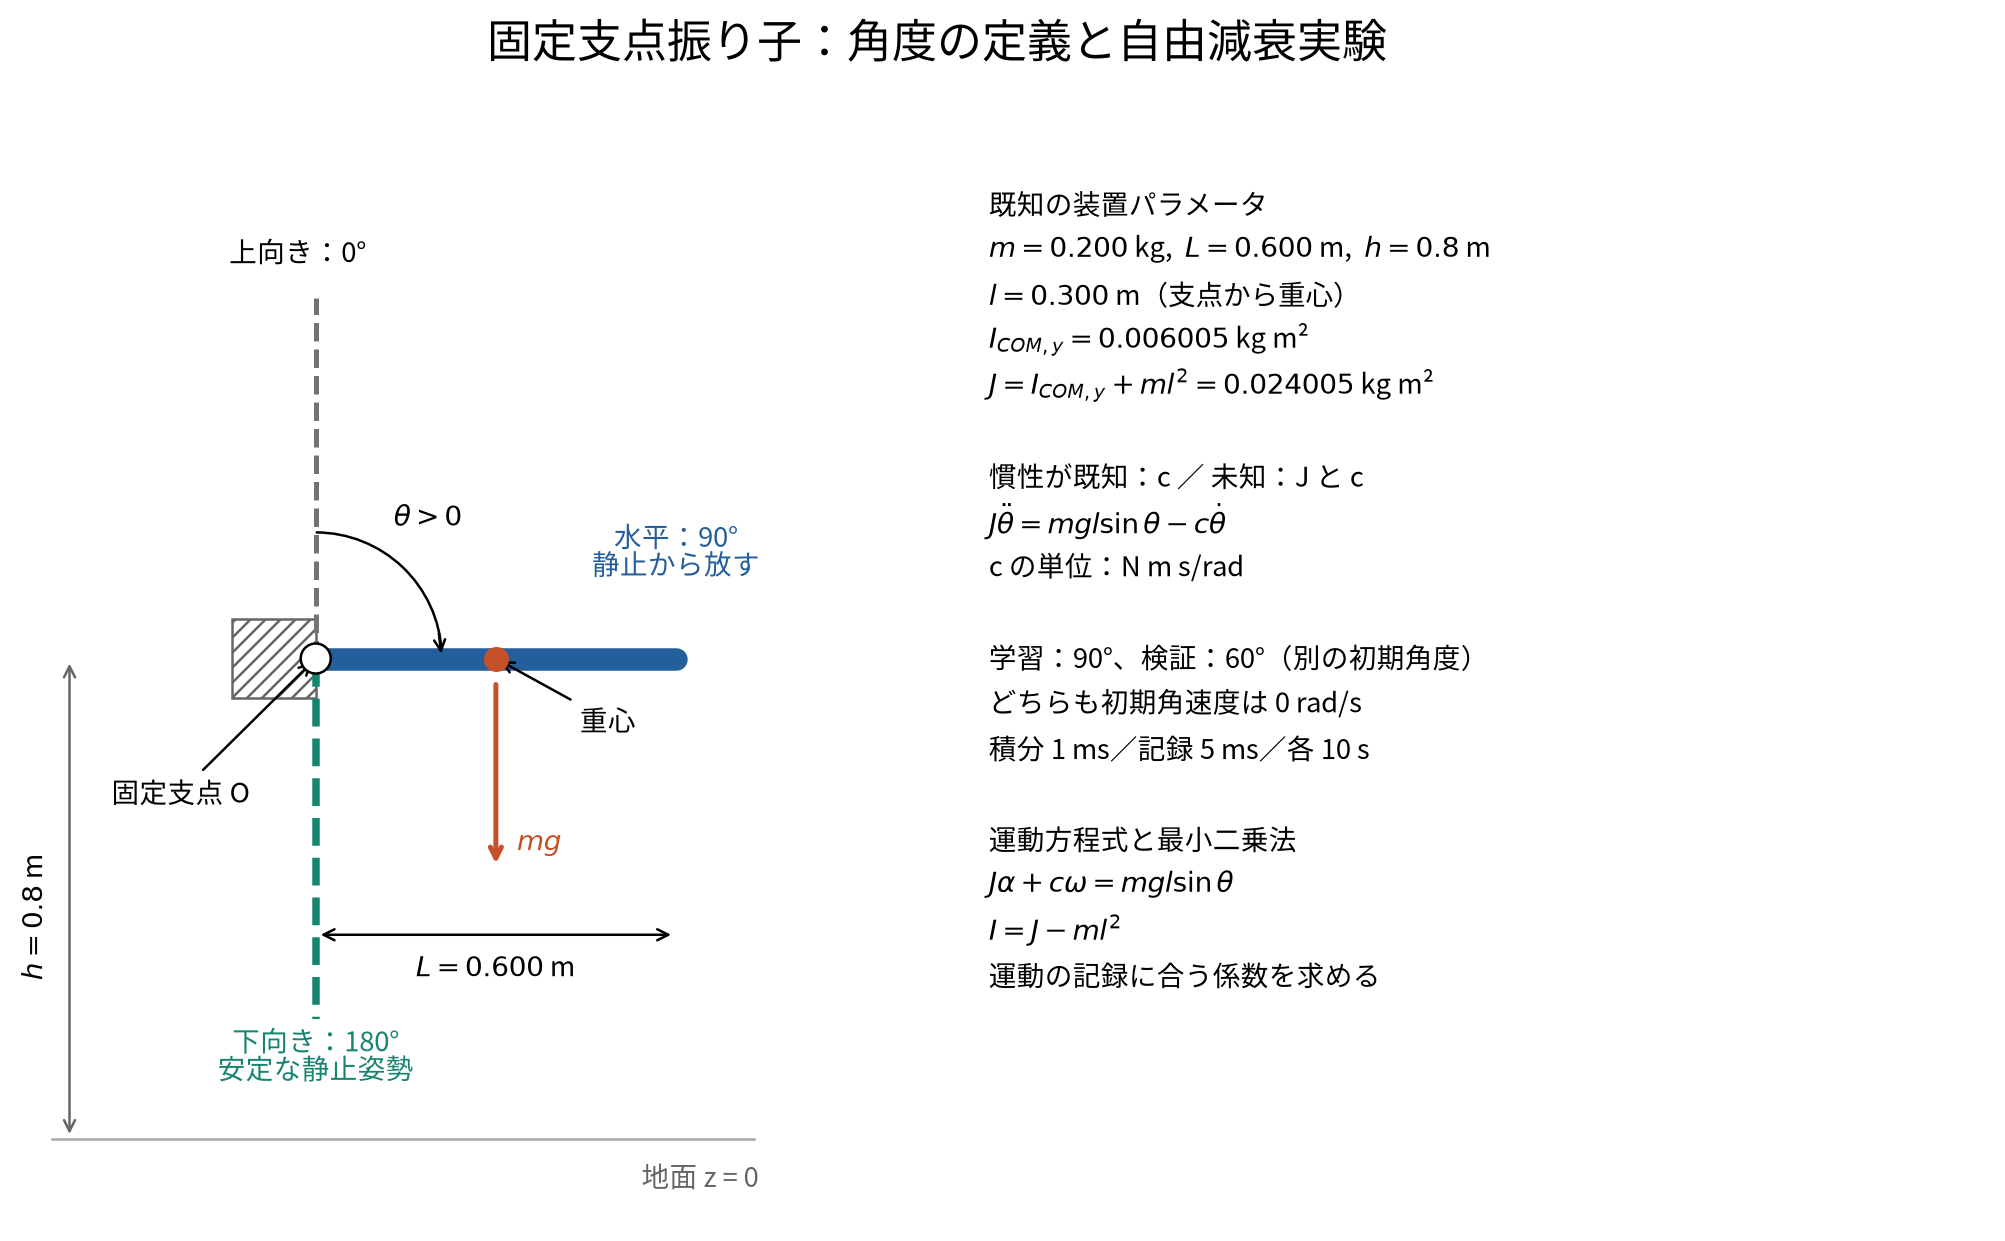

In [1]:
# @title 環境の準備（そのまま実行）
import sys, subprocess, importlib.util, importlib.metadata
if (importlib.util.find_spec("mujoco") is None
    or importlib.metadata.version("mujoco") != "3.3.3"):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "mujoco==3.3.3"])
import mujoco
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import json
from IPython.display import display
print("MuJoCo:", mujoco.__version__)
OUT = Path("pendulum_student_outputs")
OUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11, "axes.grid": True,
                     "grid.alpha": .2, "figure.dpi": 120})
# 図の軸は環境に依存しない英字表記。本文は日本語です。

MuJoCo: 3.3.3


### 実験条件
質量mと重心までの距離lは既知とします。生成用のIとcは、最後の答え合わせに使います。

In [2]:
MASS, COM, LENGTH, RADIUS = 0.2, 0.3, 0.6, 0.01
G, HEIGHT, DT = 9.81, 0.8, 0.001
I_AXIAL = MASS * RADIUS**2 / 2
REFERENCE_I = MASS * (LENGTH**2 + 3*RADIUS**2) / 12
REFERENCE_C = 0.015

In [3]:
# @title 配布モデルのXML（必要なときに開く）
reference_xml = f"""<mujoco model="reference_pendulum">
  <compiler angle="radian" inertiafromgeom="false"/>
  <option timestep="{DT}" gravity="0 0 -{G}" integrator="RK4"/>
  <worldbody>
    <body name="rod" pos="0 0 {HEIGHT}">
      <joint name="hinge" type="hinge" axis="0 1 0" damping="{REFERENCE_C}"
             frictionloss="0" armature="0" limited="false"/>
      <inertial pos="0 0 {COM}" mass="{MASS}"
                diaginertia="{REFERENCE_I} {REFERENCE_I} {I_AXIAL}"/>
      <geom type="cylinder" fromto="0 0 0 0 0 {LENGTH}" size="{RADIUS}"
            contype="0" conaffinity="0" rgba="0.15 0.4 0.7 1"/>
    </body>
  </worldbody>
</mujoco>"""

### 初期状態を置き、時間を進める
やり直すときは、この初期状態のセルから実行します。記録は5ステップごと、0.005秒間隔です。

In [4]:
reference_model = mujoco.MjModel.from_xml_string(reference_xml)
reference_data = mujoco.MjData(reference_model)
reference_data.qpos[0] = np.deg2rad(90)
reference_data.qvel[0] = 0
mujoco.mj_forward(reference_model, reference_data)

In [5]:
rows = []
for k in range(10001):
    if k % 5 == 0:
        rows.append([reference_data.time, reference_data.qpos[0], reference_data.qvel[0]])
    if k < 10000:
        mujoco.mj_step(reference_model, reference_data)
record = pd.DataFrame(rows, columns=["t", "theta", "omega"])

In [6]:
# @title 記録をグラフにする道具（そのまま実行）
def plot_motion(frame, name):
    fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
    axes[0].plot(frame.t, np.rad2deg(frame.theta), color="#2166ac")
    axes[0].axhline(180, color="gray", ls=":", label="Downward: 180 deg")
    axes[0].set_ylabel("Angle [deg]"); axes[0].legend()
    axes[1].plot(frame.t, frame.omega, color="#b35806")
    axes[1].set(xlabel="Time [s]", ylabel="Angular velocity [rad/s]")
    fig.suptitle(name.replace("_", " ")); fig.tight_layout()
    fig.savefig(OUT / f"{name}_motion.png", bbox_inches="tight")
    plt.show()

,t,theta,omega
0,0.000,1.570796,0.000000
1,0.005,1.571103,0.122408
2000,10.000,3.173541,-0.288715


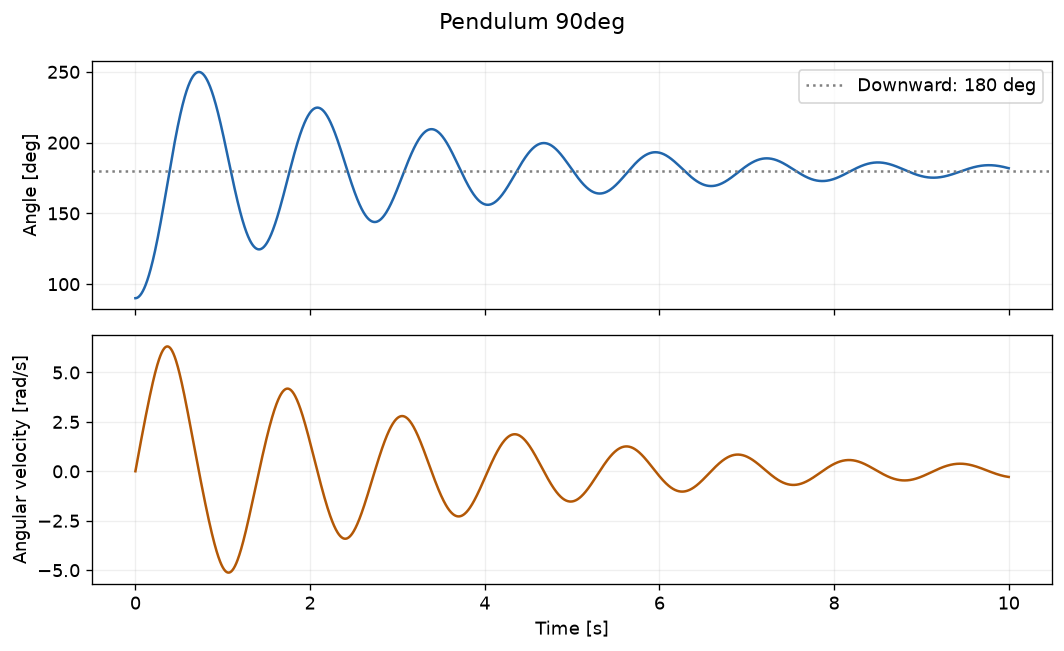

In [7]:
display(record.iloc[[0, 1, -1]])
plot_motion(record, "Pendulum_90deg")
record.to_csv(OUT / "pendulum_90deg.csv", index=False)  # 記録の保存

## 2｜運動方程式を読む
重心の位置は $x_G=l\sin\theta$、$z_G=h+l\cos\theta$ です。今回、モータのトルクは加えません。

$${\color{red}{J}}\ddot\theta={\color{blue}{m}}g{\color{blue}{l}}\sin\theta-{\color{red}{c}}\dot\theta$$

- **青：与える値** — 質量m、支点から重心までの距離l。gは重力加速度。
- **赤：求める値** — 支点回りの慣性J、粘性抵抗係数c。
- $\theta$は角度、$\dot\theta$は角速度、$\ddot\theta$は角加速度。

右辺は「重力のトルク−回転に逆らう抵抗」です。

$$J=I+ml^2\quad\Longrightarrow\quad I=J-ml^2$$

Iは重心回りの慣性です。均質な棒なら形状から理論値を求められますが、今回は**理論値を同定に渡さず、Jとcを運動から求めます。**

### どうやって二つの値を求めるか
$\omega=\dot\theta$、$\alpha=\ddot\theta$ と置くと、各時刻kで

$$J\alpha_k+c\omega_k=mgl\sin\theta_k.$$

記録から角加速度を求めます。

$$\alpha_k\approx\frac{\omega_{k+1}-\omega_{k-1}}{2\Delta t}$$

全時刻の式にできるだけ合うJとcを選びます。これが最小二乗法です。

$$(\hat J,\hat c)=\underset{J,c}{\operatorname{argmin}}
\sum_k\left(J\alpha_k+c\omega_k-mgl\sin\theta_k\right)^2$$

帽子は推定した値を表します。

## 3｜計算する前に、式を説明する
次の3点を、自分の言葉で説明してください。

1. 角加速度は、記録のどの列からどう求めるか。
2. Jとcが掛かる量は何か。最小二乗法は何のずれを小さくするか。
3. 求めたJと、重心回りのIはどう違うか。

**AIへの相談例：**「この振子の運動方程式からJとcを求めたいです。記録のt・theta・omegaから何を計算するか、式と一行ずつ対応させて説明してください。」

## 4｜パラメータを推定する
### ① 角加速度を作る
最初と最後の行は両隣がないので除きます。角度・角速度も同じ中央の時刻にそろえます。

In [8]:
t = record["t"].to_numpy()
theta = record["theta"].to_numpy()
omega = record["omega"].to_numpy()
dt = t[1] - t[0]
alpha = (omega[2:] - omega[:-2]) / (2 * dt)
theta_mid, omega_mid = theta[1:-1], omega[1:-1]

### ② 式を並べ、Jとcを求める
$$A=\begin{bmatrix}\alpha_1&\omega_1\\\alpha_2&\omega_2\\\vdots&\vdots\end{bmatrix},\qquad
b=\begin{bmatrix}mgl\sin\theta_1\\mgl\sin\theta_2\\\vdots\end{bmatrix},\qquad
A\begin{bmatrix}J\\c\end{bmatrix}\approx b.$$

`column_stack`は2列を横に並べます。`lstsq`は二乗和が最小になる係数を求め、先頭の返り値にJ・cがこの順で入ります。

In [9]:
A = np.column_stack([alpha, omega_mid])
b = MASS * G * COM * np.sin(theta_mid)
fit = np.linalg.lstsq(A, b, rcond=None)
J_est, c_est = fit[0]
I_est = J_est - MASS * COM**2
print("推定した J, I, c：", J_est, I_est, c_est)

推定した J, I, c： 0.02400717146608962 0.00600717146608962 0.014999235707515778


### ③ 生成時の値と比べる
ここで初めて生成用のI・cを答え合わせに使います。設定値と推定値の差を見てください。数値積分と差分による誤差があるため、完全には一致しません。

In [10]:
display(pd.DataFrame({
    "parameter": ["J [kg m2]", "I [kg m2]", "c [N m s/rad]"],
    "setting": [REFERENCE_I + MASS*COM**2, REFERENCE_I, REFERENCE_C],
    "estimate": [J_est, I_est, c_est],
}))

,parameter,setting,estimate
0,J [kg m2],0.024005,0.024007
1,I [kg m2],0.006005,0.006007
2,c [N m s/rad],0.015000,0.014999


**ここまでで完了です。** 推定結果の表を残し、手順3の三つの問いに答えてください。